# 응용 05 · 값과 근거의 분리 평가

`05_field_metrics.py`의 A05 구현을 바탕으로 모의 응답 15개의 값 일치 여부와 근거 존재 여부를 따로 평가합니다. 정답은 응답 생성에 사용하지 않고 평가 단계에서만 읽습니다.

저장소 내부의 Python 커널에서 순서대로 실행하세요. pandas, Matplotlib, IPython이 필요합니다. 차트는 한글 폰트 없이 표시할 수 있도록 영문으로 작성했습니다. 결과는 메모리에서 확인하며 마지막 CSV 저장 셀은 선택 사항입니다.

## 1. 두 가지 질문을 구분하기

| 지표 | 비교 대상 | 의미 |
|---|---|---|
| `exact` | `answer == truth` | 제공 답과 해당 문서·필드의 정답이 같은가? |
| `evidence_found` | `evidence in OCR 원문` | 제공 근거 문자열이 같은 문서의 OCR에 있는가? |
| 두 조건 모두 | `exact & evidence_found` | 값 일치와 근거 발견을 모두 만족하는가? |
| `review` | `not evidence_found` | 원본 코드에서 근거가 없어 검토 대상으로 표시했는가? |

`review`는 정답 비교 결과 전체를 반영하는 지표가 아닙니다. 정답과 다른 응답도 별도로 확인해야 합니다.


In [1]:
from pathlib import Path
from io import StringIO
import json
import textwrap
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from IPython.display import display

start = Path.cwd().resolve()
project = next((p for p in [start, *start.parents]
                if (p / '20261109/02_intermediate/05_field_metrics.py').is_file()), None)
if project is None:
    raise FileNotFoundError('저장소 내부에서 실행하세요.')
base = project / '20261109/02_intermediate'
lesson = json.loads((base / 'data/lesson.json').read_text(encoding='utf-8'))
print('문서 수:', len(lesson['documents']))


문서 수: 5


## 2. 현재 구현과 자료형 확인

필드명으로 정답을 선택한 뒤 `==`로 비교합니다.

```python
field = item['field']
answer = item['answer']
evidence = item['evidence']
truth = doc['truth'][field]
exact = answer == truth
```

`json.loads()`가 JSON 문자열과 숫자를 Python의 `str`, `int`로 읽습니다. 현재 데이터에서는 예측값과 정답의 자료형이 이미 대응하므로 추가 파싱이나 형변환이 필요하지 않습니다. 문자열의 공백과 대소문자도 비교에 영향을 줍니다.

`in`으로 문자열을 검색할 때 정수를 직접 넣을 수는 없지만, 정수끼리 `==`로 비교하는 것은 가능합니다. `str(answer) in evidence`로 바꾸면 오류는 피할 수 있어도 검사 목적이 달라집니다.


In [2]:
type_rows = []
for name, doc in lesson['documents'].items():
    for item in doc['mock_vlm']['responses']:
        truth = doc['truth'][item['field']]
        type_rows.append({'document_id': name, 'field': item['field'],
                          'answer': repr(item['answer']), 'truth': repr(truth),
                          'answer_type': type(item['answer']).__name__,
                          'truth_type': type(truth).__name__})
display(pd.DataFrame(type_rows))


,document_id,field,answer,truth,answer_type,truth_type
0,doc01,issued_at,'2026-11-01','2026-11-01',str,str
1,doc01,supplier,'BLUE CAFE','BLUE CAFE',str,str
2,doc01,total_amount,27000,27000,int,int
3,doc02,issued_at,'2026-11-02','2026-11-02',str,str
4,doc02,supplier,'PINE BOOKS','PINE BOOKS',str,str
5,doc02,total_amount,18000,18000,int,int
6,doc03,issued_at,'2026-11-03','2026-11-03',str,str
7,doc03,supplier,'ALPHA STUDIO','ALPHA STUDIO',str,str
8,doc03,total_amount,33000,33000,int,int
9,doc04,issued_at,'2026-11-04','2026-11-04',str,str


## 3. 원본 A05 블록으로 평가

현재 Python 파일의 TODO 블록을 읽어 실행합니다. 원본과 같은 결과 열을 만들고, 설명용으로 답·정답·근거를 포함한 표도 따로 만듭니다.


In [3]:
source = (base / '05_field_metrics.py').read_text(encoding='utf-8')
# TODO 설명 첫 줄은 제외하고 나머지 주석과 구현을 읽습니다.
block = source.split('# TODO A05:', 1)[1].split('\n', 1)[1].split('# TODO 끝 A05', 1)[0]
block = textwrap.dedent(block)
rows, details = [], []
for name, doc in lesson['documents'].items():
    for item in doc['mock_vlm']['responses']:
        scope = {'item': item, 'doc': doc}
        exec(compile(block, str(base / '05_field_metrics.py'), 'exec'), scope)
        exact = scope['exact']
        grounded = item['evidence'] in doc['ocr']['text']
        row = {'document_id': name, 'field': item['field'], 'backend': 'mock',
               'exact': exact, 'evidence_found': grounded, 'review': not grounded}
        rows.append(row)
        details.append({**row, 'answer': item['answer'],
                        'truth': doc['truth'][item['field']], 'evidence': item['evidence']})
table = pd.DataFrame(rows)
detail = pd.DataFrame(details)
detail['both'] = detail['exact'] & detail['evidence_found']
display(detail)
print('값 일치:', int(table['exact'].sum()), '/', len(table))
print('값과 문자열 근거:', int((table['exact'] & table['evidence_found']).sum()), '/', len(table))
print('추론 지연시간: N/A (mock)')


,document_id,field,backend,exact,evidence_found,review,answer,truth,evidence,both
0,doc01,issued_at,mock,True,True,False,2026-11-01,2026-11-01,DATE: 2026-11-01,True
1,doc01,supplier,mock,True,True,False,BLUE CAFE,BLUE CAFE,SUPPLIER: BLUE CAFE,True
2,doc01,total_amount,mock,True,True,False,27000,27000,TOTAL: 27000,True
3,doc02,issued_at,mock,True,True,False,2026-11-02,2026-11-02,DATE: 2026-11-02,True
4,doc02,supplier,mock,True,True,False,PINE BOOKS,PINE BOOKS,SUPPLIER: PINE BOOKS,True
5,doc02,total_amount,mock,True,True,False,18000,18000,TOTAL: 18000,True
6,doc03,issued_at,mock,True,True,False,2026-11-03,2026-11-03,DATE: 2026-11-03,True
7,doc03,supplier,mock,True,True,False,ALPHA STUDIO,ALPHA STUDIO,SUPPLIER: ALPHA STUDIO,True
8,doc03,total_amount,mock,True,True,False,33000,33000,TOTAL: 33000,True
9,doc04,issued_at,mock,True,True,False,2026-11-04,2026-11-04,DATE: 2026-11-04,True


값 일치: 14 / 15
값과 문자열 근거: 13 / 15
추론 지연시간: N/A (mock)


## 4. 문서·필드별 결과 시각화

각 칸을 세 가지 상태로 구분합니다. 값이 틀린 응답과 값은 맞지만 근거가 없는 응답을 서로 다른 색으로 표시합니다. 현재 데이터에는 값이 틀리면서 근거 문자열은 발견되는 사례가 없지만, 그런 경우에도 값 불일치로 표시됩니다.


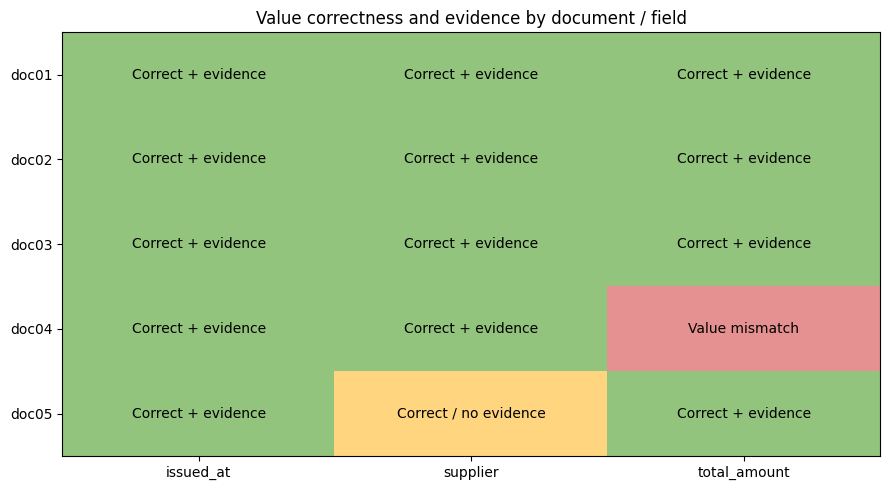

In [4]:
fields = ['issued_at', 'supplier', 'total_amount']
view = detail.copy()
view['status'] = [2 if row.both else 1 if row.exact else 0 for row in view.itertuples()]
matrix = view.pivot(index='document_id', columns='field', values='status')[fields]
fig, ax = plt.subplots(figsize=(9, 5))
ax.imshow(matrix, cmap=ListedColormap(['#e69191', '#ffd580', '#93c47d']), vmin=0, vmax=2, aspect='auto')
ax.set_xticks(range(3), fields)
ax.set_yticks(range(len(matrix)), matrix.index)
labels = ['Value mismatch', 'Correct / no evidence', 'Correct + evidence']
for r in range(len(matrix)):
    for c in range(3):
        ax.text(c, r, labels[int(matrix.iloc[r, c])], ha='center', va='center', fontsize=10)
ax.set_title('Value correctness and evidence by document / field')
fig.tight_layout()
display(fig)
plt.close(fig)


## 5. 지표별 집계

불리언 열의 `sum()`은 `True` 개수를 셉니다. `&`는 pandas 열의 같은 행끼리 AND 연산을 수행합니다.

아래 막대의 분모는 모두 15개 응답입니다. 근거 발견률과 값 일치율은 서로 다른 검사 결과이므로 같은 정확도로 해석하면 안 됩니다.


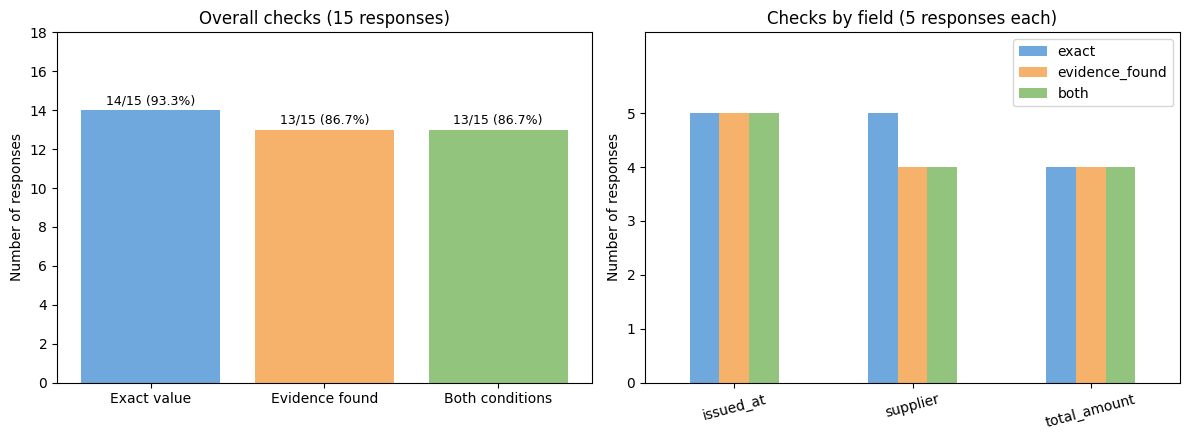

In [5]:
metrics = {'Exact value': int(table['exact'].sum()),
           'Evidence found': int(table['evidence_found'].sum()),
           'Both conditions': int(detail['both'].sum())}
by_field = detail.groupby('field')[['exact', 'evidence_found', 'both']].sum().reindex(fields)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
bars = axes[0].bar(list(metrics), list(metrics.values()), color=['#6fa8dc', '#f6b26b', '#93c47d'])
axes[0].set_ylim(0, len(table) + 3)
axes[0].set_ylabel('Number of responses')
axes[0].set_title('Overall checks (15 responses)')
for bar, value in zip(bars, metrics.values()):
    axes[0].text(bar.get_x() + bar.get_width()/2, value + 0.3,
                 f'{value}/{len(table)} ({value/len(table):.1%})', ha='center', fontsize=9)
by_field.plot.bar(ax=axes[1], color=['#6fa8dc', '#f6b26b', '#93c47d'], rot=15)
axes[1].set_ylim(0, 6.5)
axes[1].set_yticks(range(6))
axes[1].set_title('Checks by field (5 responses each)')
axes[1].set_xlabel('')
axes[1].set_ylabel('Number of responses')
fig.tight_layout()
display(fig)
plt.close(fig)


## 6. 이전 방식과 올바른 비교의 차이

`str(answer) in evidence`는 답이 제공 근거 문자열 안에 있는지 검사합니다. 실제 정답을 참조하지 않으므로 값 일치 지표로 쓸 수 없습니다.

- `doc04 / total_amount`: 답은 `99999`, 정답은 `12500`입니다. 근거에 `99999`가 적혀 있어도 오답입니다.
- `doc05 / supplier`: 답과 정답은 모두 `LIME LAB`입니다. 근거 문자열에 이름이 없어도 값 자체는 맞습니다.

두 방식은 우연히 총 14건으로 집계되지만 위 두 항목의 판정이 뒤바뀝니다. 합계만 확인하면 오류를 놓칠 수 있습니다.


In [6]:
comparison = detail.copy()
comparison['answer_in_evidence'] = [str(r.answer) in r.evidence for r in comparison.itertuples()]
display(comparison.loc[comparison['answer_in_evidence'] != comparison['exact'],
                       ['document_id', 'field', 'answer', 'truth', 'evidence',
                        'answer_in_evidence', 'exact', 'evidence_found']])
print('이전 포함 검사 합계:', int(comparison['answer_in_evidence'].sum()))
print('정답 비교 합계:', int(comparison['exact'].sum()))


,document_id,field,answer,truth,evidence,answer_in_evidence,exact,evidence_found
11,doc04,total_amount,99999,12500,TOTAL: 99999,True,False,False
13,doc05,supplier,LIME LAB,LIME LAB,not visible in this crop,False,True,False


이전 포함 검사 합계: 14
정답 비교 합계: 14


## 7. 결과 확인과 선택적 CSV 저장

현재 제공 데이터의 기대 결과는 값 일치 14/15, 근거 발견 13/15, 두 조건 모두 만족 13/15입니다. 아래에서는 원본 코드의 집계와 별개로 정답 비교를 직접 계산해 결과를 확인하고, CSV를 메모리에서 다시 읽어 저장 형식을 점검합니다.

마지막 주석을 해제하면 원본과 같은 `outputs/p05_scores.csv`를 생성하거나 덮어씁니다. 출력 CSV는 커밋 대상에서 제외합니다.


In [7]:
assert len(table) == 15
for row in detail.itertuples():
    assert row.exact == (row.answer == lesson['documents'][row.document_id]['truth'][row.field])
    assert row.review == (not row.evidence_found)
assert int(table['exact'].sum()) == 14
assert int(table['evidence_found'].sum()) == 13
assert int(detail['both'].sum()) == 13
csv_text = table.to_csv(index=False)
restored = pd.read_csv(StringIO(csv_text))
pd.testing.assert_frame_equal(restored, table)
print('검증 통과: 정답 비교 · 근거 검사 · 집계 · CSV 왕복 변환')

# out = base / 'outputs'
# out.mkdir(exist_ok=True)
# table.to_csv(out / 'p05_scores.csv', index=False, encoding='utf-8-sig')


검증 통과: 정답 비교 · 근거 검사 · 집계 · CSV 왕복 변환


## 8. 해석과 설명 질문

모의 응답에서 값이 맞더라도 근거가 없을 수 있으므로 두 지표를 나누어 보고합니다. `evidence_found`는 단순 문자열 포함 검사이며, 의미적으로 답을 뒷받침하는지나 이미지에서 실제 근거가 보이는지까지 보장하지 않습니다.

**모의 응답 파일 읽기 시간을 실제 모델 추론시간이라고 할 수 있나요?** 아니요. 이 코드는 미리 작성된 응답을 읽고 비교할 뿐 모델을 실행하지 않습니다. 따라서 추론 지연시간은 `N/A (mock)`이고 위 비율을 실제 VLM의 성능으로 일반화할 수 없습니다.
